# Data Frequency Analysis - Aug29 L2

This notebook analyzes the temporal characteristics of the data:
- Frequency of data points
- Frequency drift over time
- Long disconnections/gaps
- Data ordering issues


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set up paths
data_path = Path('../data/Aug29/2_DyF_L2.jsonl')
print(f"Loading data from: {data_path}")


Loading data from: ..\data\Aug29\2_DyF_L2.jsonl


In [2]:
# Load the JSONL file
data_points = []
with open(data_path, 'r') as f:
    for line in f:
        if line.strip():  # Skip empty lines
            data_points.append(json.loads(line))

print(f"Loaded {len(data_points)} data points")
print(f"First timestamp: {data_points[0]['timestamp']}")
print(f"Last timestamp: {data_points[-1]['timestamp']}")


Loaded 48745 data points
First timestamp: 1756487196.7640388
Last timestamp: 1756487391.7392745


In [3]:
# Extract timestamps and calculate intervals
timestamps = np.array([dp['timestamp'] for dp in data_points])
delta_times = np.array([dp['delta_time'] for dp in data_points])

# Calculate actual time intervals between consecutive points
actual_intervals = np.diff(timestamps)

print("=== Basic Statistics ===")
print(f"Total data points: {len(data_points)}")
print(f"Total duration: {timestamps[-1] - timestamps[0]:.2f} seconds")
print(f"Average interval (from delta_time): {np.mean(delta_times[1:]):.6f} seconds")
print(f"Average actual interval (from timestamps): {np.mean(actual_intervals):.6f} seconds")
print(f"Expected frequency: {1.0/np.mean(delta_times[1:]):.2f} Hz")
print(f"Actual frequency: {1.0/np.mean(actual_intervals):.2f} Hz")


=== Basic Statistics ===
Total data points: 48745
Total duration: 194.98 seconds
Average interval (from delta_time): 0.004000 seconds
Average actual interval (from timestamps): 0.004000 seconds
Expected frequency: 250.00 Hz
Actual frequency: 250.00 Hz


In [4]:
# Check if data is in order
is_ordered = np.all(timestamps[:-1] <= timestamps[1:])
print(f"\n=== Ordering Check ===")
print(f"Data is in chronological order: {is_ordered}")

if not is_ordered:
    # Find indices where timestamps decrease
    out_of_order_indices = np.where(timestamps[:-1] > timestamps[1:])[0]
    print(f"Found {len(out_of_order_indices)} out-of-order transitions")
    print(f"Indices: {out_of_order_indices[:10]}")  # Show first 10



=== Ordering Check ===
Data is in chronological order: True


In [5]:
# Analyze frequency drift - calculate rolling statistics
window_size = 1000  # samples

frequencies = 1.0 / actual_intervals
rolling_mean_freq = pd.Series(frequencies).rolling(window=window_size, center=True).mean()
rolling_std_freq = pd.Series(frequencies).rolling(window=window_size, center=True).std()

print(f"\n=== Frequency Drift Analysis ===")
print(f"Overall mean frequency: {np.mean(frequencies):.4f} Hz")
print(f"Overall std frequency: {np.std(frequencies):.4f} Hz")
print(f"Min frequency: {np.min(frequencies):.4f} Hz")
print(f"Max frequency: {np.max(frequencies):.4f} Hz")
print(f"Frequency range: {np.max(frequencies) - np.min(frequencies):.4f} Hz")
print(f"Frequency coefficient of variation: {np.std(frequencies)/np.mean(frequencies)*100:.2f}%")



=== Frequency Drift Analysis ===
Overall mean frequency: 250.8733 Hz
Overall std frequency: 15.7259 Hz
Min frequency: 183.5983 Hz
Max frequency: 388.2177 Hz
Frequency range: 204.6194 Hz
Frequency coefficient of variation: 6.27%


In [6]:
# Identify long disconnections/gaps
mean_interval = np.mean(actual_intervals)
std_interval = np.std(actual_intervals)
threshold = mean_interval + 3 * std_interval  # 3 sigma threshold

large_gaps = np.where(actual_intervals > threshold)[0]
large_gap_sizes = actual_intervals[large_gaps]

print(f"\n=== Gap Analysis ===")
print(f"Mean interval: {mean_interval:.6f} seconds")
print(f"Std interval: {std_interval:.6f} seconds")
print(f"Threshold for large gaps (mean + 3*std): {threshold:.6f} seconds")
print(f"Number of large gaps (> threshold): {len(large_gaps)}")

if len(large_gaps) > 0:
    print(f"\nLargest gaps:")
    sorted_gaps = np.argsort(actual_intervals)[::-1][:10]  # Top 10 largest gaps
    for idx in sorted_gaps:
        gap_time = actual_intervals[idx]
        gap_size_ratio = gap_time / mean_interval
        print(f"  Gap at index {idx}: {gap_time:.6f} seconds ({gap_size_ratio:.1f}x mean interval)")



=== Gap Analysis ===
Mean interval: 0.004000 seconds
Std interval: 0.000226 seconds
Threshold for large gaps (mean + 3*std): 0.004678 seconds
Number of large gaps (> threshold): 500

Largest gaps:
  Gap at index 29718: 0.005447 seconds (1.4x mean interval)
  Gap at index 12665: 0.005428 seconds (1.4x mean interval)
  Gap at index 9908: 0.005386 seconds (1.3x mean interval)
  Gap at index 12150: 0.005371 seconds (1.3x mean interval)
  Gap at index 2770: 0.005357 seconds (1.3x mean interval)
  Gap at index 2911: 0.005346 seconds (1.3x mean interval)
  Gap at index 14531: 0.005339 seconds (1.3x mean interval)
  Gap at index 28802: 0.005337 seconds (1.3x mean interval)
  Gap at index 6155: 0.005325 seconds (1.3x mean interval)
  Gap at index 16613: 0.005320 seconds (1.3x mean interval)


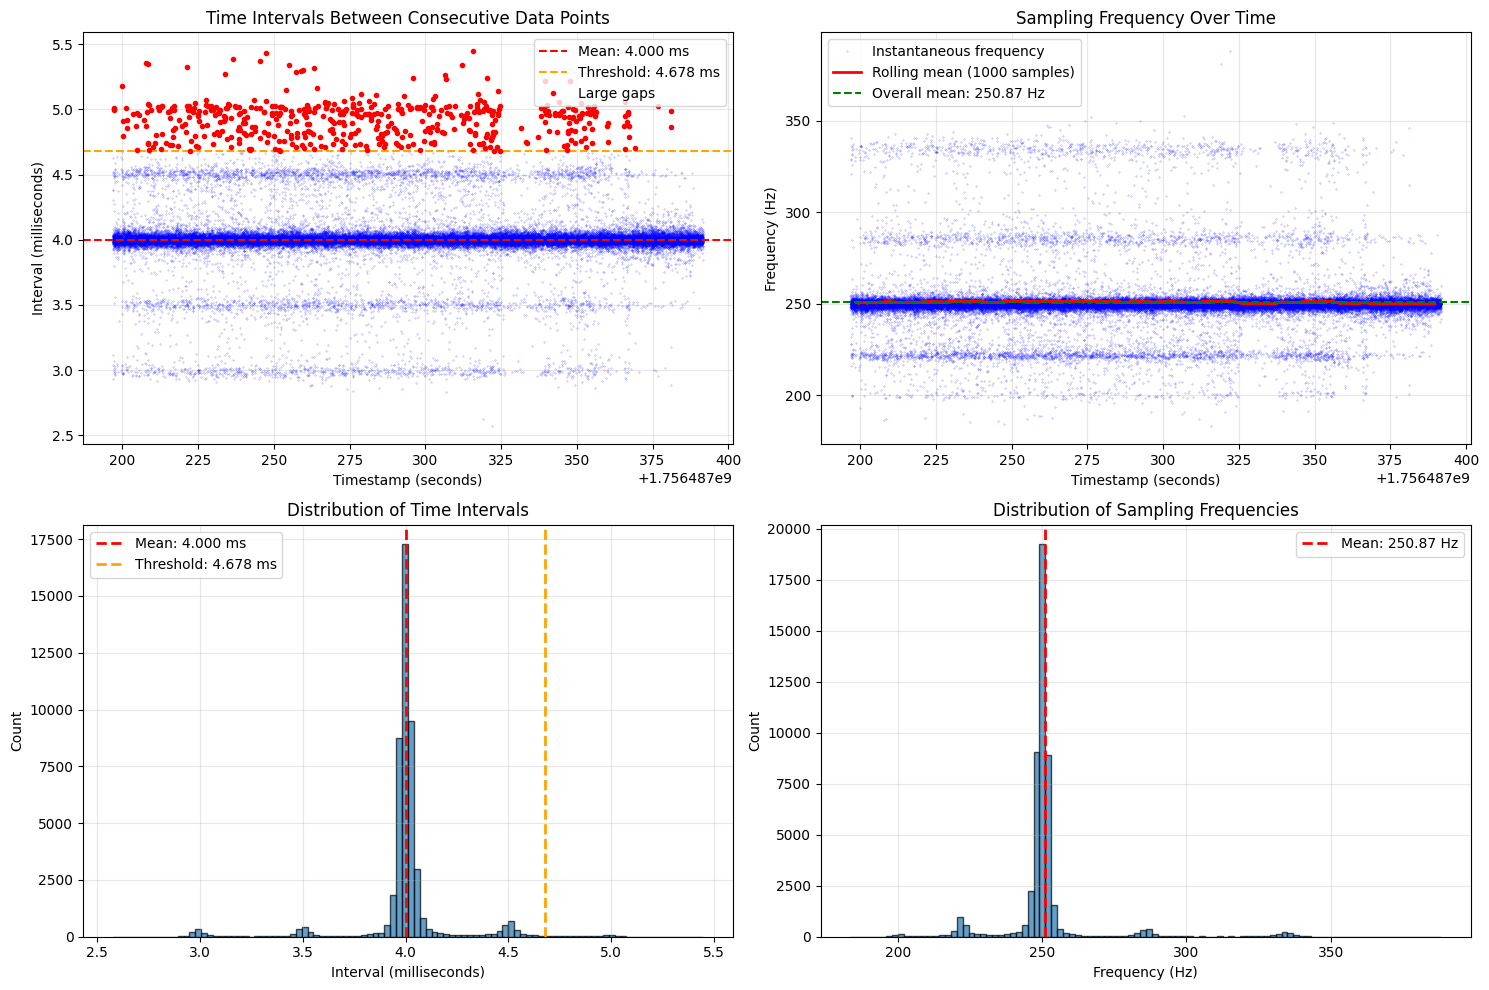

In [7]:
# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Time intervals over time
ax1 = axes[0, 0]
ax1.plot(timestamps[1:], actual_intervals * 1000, 'b.', markersize=0.5, alpha=0.5)
ax1.axhline(y=mean_interval * 1000, color='r', linestyle='--', label=f'Mean: {mean_interval*1000:.3f} ms')
ax1.axhline(y=threshold * 1000, color='orange', linestyle='--', label=f'Threshold: {threshold*1000:.3f} ms')
if len(large_gaps) > 0:
    ax1.plot(timestamps[large_gaps+1], actual_intervals[large_gaps] * 1000, 'ro', markersize=3, label='Large gaps')
ax1.set_xlabel('Timestamp (seconds)')
ax1.set_ylabel('Interval (milliseconds)')
ax1.set_title('Time Intervals Between Consecutive Data Points')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Frequency over time
ax2 = axes[0, 1]
ax2.plot(timestamps[1:], frequencies, 'b.', markersize=0.5, alpha=0.5, label='Instantaneous frequency')
if len(rolling_mean_freq) > 0:
    ax2.plot(timestamps[1:], rolling_mean_freq, 'r-', linewidth=2, label=f'Rolling mean ({window_size} samples)')
ax2.axhline(y=np.mean(frequencies), color='g', linestyle='--', label=f'Overall mean: {np.mean(frequencies):.2f} Hz')
ax2.set_xlabel('Timestamp (seconds)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Sampling Frequency Over Time')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Histogram of intervals
ax3 = axes[1, 0]
ax3.hist(actual_intervals * 1000, bins=100, edgecolor='black', alpha=0.7)
ax3.axvline(x=mean_interval * 1000, color='r', linestyle='--', linewidth=2, label=f'Mean: {mean_interval*1000:.3f} ms')
ax3.axvline(x=threshold * 1000, color='orange', linestyle='--', linewidth=2, label=f'Threshold: {threshold*1000:.3f} ms')
ax3.set_xlabel('Interval (milliseconds)')
ax3.set_ylabel('Count')
ax3.set_title('Distribution of Time Intervals')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Histogram of frequencies
ax4 = axes[1, 1]
ax4.hist(frequencies, bins=100, edgecolor='black', alpha=0.7)
ax4.axvline(x=np.mean(frequencies), color='r', linestyle='--', linewidth=2, label=f'Mean: {np.mean(frequencies):.2f} Hz')
ax4.set_xlabel('Frequency (Hz)')
ax4.set_ylabel('Count')
ax4.set_title('Distribution of Sampling Frequencies')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
# Summary statistics table
summary_df = pd.DataFrame({
    'Metric': [
        'Total data points',
        'Total duration (s)',
        'Mean interval (ms)',
        'Std interval (ms)',
        'Mean frequency (Hz)',
        'Std frequency (Hz)',
        'Min frequency (Hz)',
        'Max frequency (Hz)',
        'Frequency CV (%)',
        'Is in order',
        'Large gaps count',
        'Max gap size (ms)'
    ],
    'Value': [
        len(data_points),
        f"{timestamps[-1] - timestamps[0]:.2f}",
        f"{mean_interval * 1000:.3f}",
        f"{std_interval * 1000:.3f}",
        f"{np.mean(frequencies):.4f}",
        f"{np.std(frequencies):.4f}",
        f"{np.min(frequencies):.4f}",
        f"{np.max(frequencies):.4f}",
        f"{np.std(frequencies)/np.mean(frequencies)*100:.2f}",
        str(is_ordered),
        len(large_gaps),
        f"{np.max(actual_intervals) * 1000:.3f}" if len(actual_intervals) > 0 else "N/A"
    ]
})

print("\n=== Summary Statistics ===")
print(summary_df.to_string(index=False))



=== Summary Statistics ===
             Metric    Value
  Total data points    48745
 Total duration (s)   194.98
 Mean interval (ms)    4.000
  Std interval (ms)    0.226
Mean frequency (Hz) 250.8733
 Std frequency (Hz)  15.7259
 Min frequency (Hz) 183.5983
 Max frequency (Hz) 388.2177
   Frequency CV (%)     6.27
        Is in order     True
   Large gaps count      500
  Max gap size (ms)    5.447



=== Delta Time Field vs Actual Timestamp Differences ===
Mean difference: 0.000000 ms
Max difference: 0.000000 ms
Std difference: 0.000000 ms


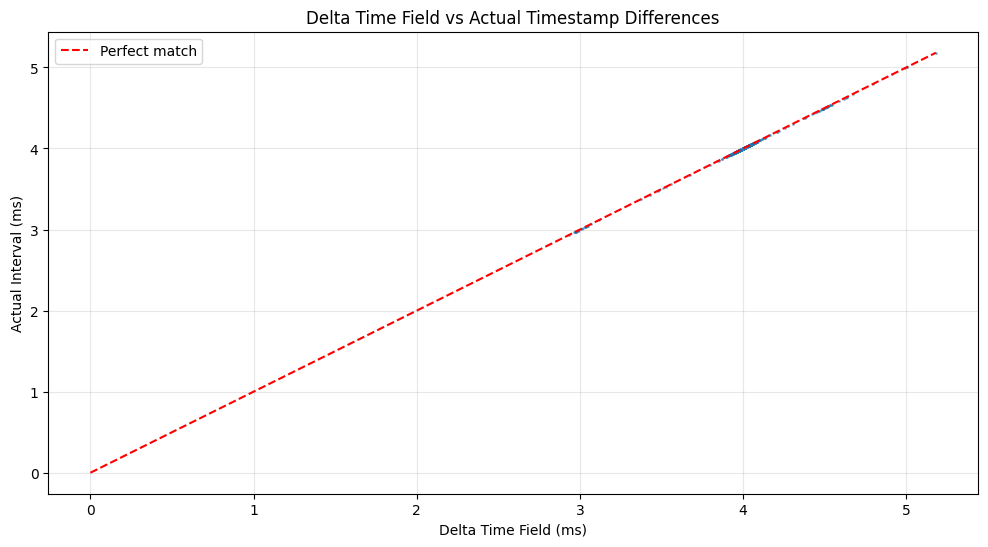

In [9]:
# Additional analysis: Compare delta_time field vs actual timestamp differences
print("\n=== Delta Time Field vs Actual Timestamp Differences ===")
delta_time_actual = delta_times[1:]  # Skip first entry (no previous point)
comparison_df = pd.DataFrame({
    'delta_time_field': delta_time_actual[:1000],  # First 1000 for comparison
    'actual_interval': actual_intervals[:1000]
})

comparison_df['difference'] = comparison_df['actual_interval'] - comparison_df['delta_time_field']
comparison_df['difference_ms'] = comparison_df['difference'] * 1000

print(f"Mean difference: {comparison_df['difference'].mean()*1000:.6f} ms")
print(f"Max difference: {comparison_df['difference'].max()*1000:.6f} ms")
print(f"Std difference: {comparison_df['difference'].std()*1000:.6f} ms")

# Plot comparison
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(comparison_df['delta_time_field'] * 1000, comparison_df['actual_interval'] * 1000, 
           alpha=0.5, s=1)
ax.plot([0, comparison_df['delta_time_field'].max() * 1000], 
        [0, comparison_df['actual_interval'].max() * 1000], 
        'r--', label='Perfect match')
ax.set_xlabel('Delta Time Field (ms)')
ax.set_ylabel('Actual Interval (ms)')
ax.set_title('Delta Time Field vs Actual Timestamp Differences')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()
